In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# DOANH THU, SỐ CHƯƠNG TRÌNH KHUYẾN MÃI VÀ TỔNG LƯỢNG ĐƠN HÀNG QUA CÁC MỐC THỜI GIAN

# Lợi nhuận thu được

In [4]:
dfSale =  pd.read_csv("Analytical/sales.csv")
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     3833 non-null   object 
 1   Revenue  3833 non-null   float64
 2   COGS     3833 non-null   float64
dtypes: float64(2), object(1)
memory usage: 90.0+ KB


In [5]:
dfSale["Date"] = pd.to_datetime(dfSale["Date"])
dfSale["Profit"] = dfSale["Revenue"] - dfSale["COGS"]
dfSale["yearMonth"] = dfSale["Date"].dt.strftime("%Y-%m")
dfSale["year"] = dfSale["Date"].dt.year
dfSale["month"] = dfSale["Date"].dt.month
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       3833 non-null   datetime64[ns]
 1   Revenue    3833 non-null   float64       
 2   COGS       3833 non-null   float64       
 3   Profit     3833 non-null   float64       
 4   yearMonth  3833 non-null   object        
 5   year       3833 non-null   int32         
 6   month      3833 non-null   int32         
dtypes: datetime64[ns](1), float64(3), int32(2), object(1)
memory usage: 179.8+ KB


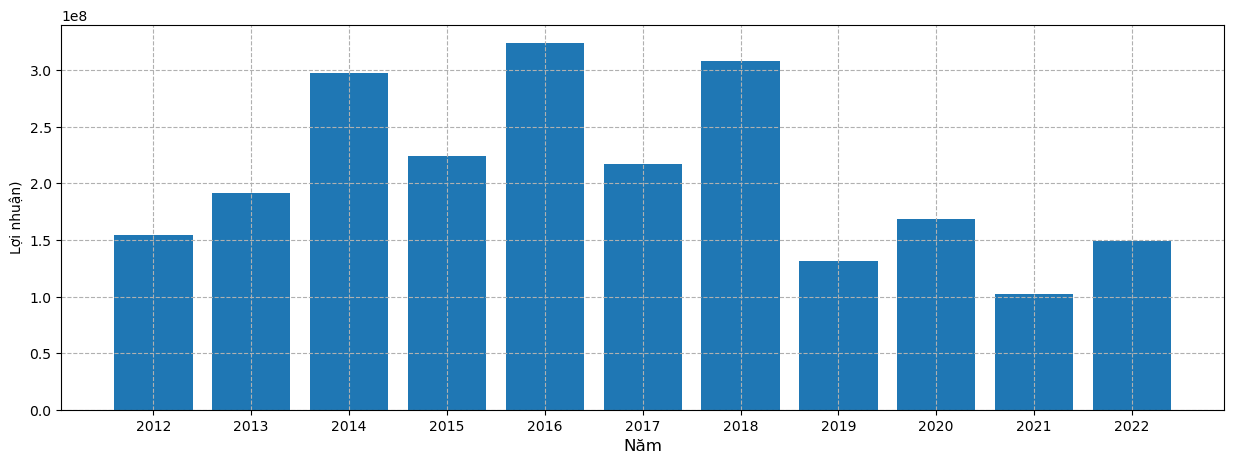

In [6]:
profitbyYear = dfSale.groupby("year")["Profit"].sum()
# year = dfSale[]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    profitbyYear.index,
    profitbyYear.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(profitbyYear.index),max(profitbyYear.index)+1))
plt.show()

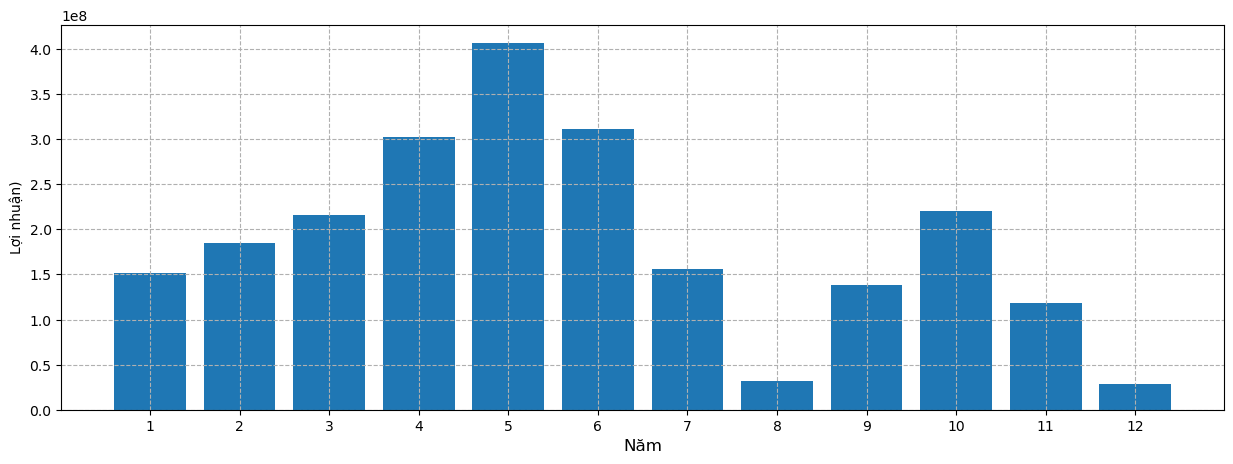

In [7]:
profitbyMonth = dfSale.groupby("month")["Profit"].sum()
profitbyMonth
# year = dfSale[]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    profitbyMonth.index,
    profitbyMonth.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(profitbyMonth.index),max(profitbyMonth.index)+1))
plt.show()

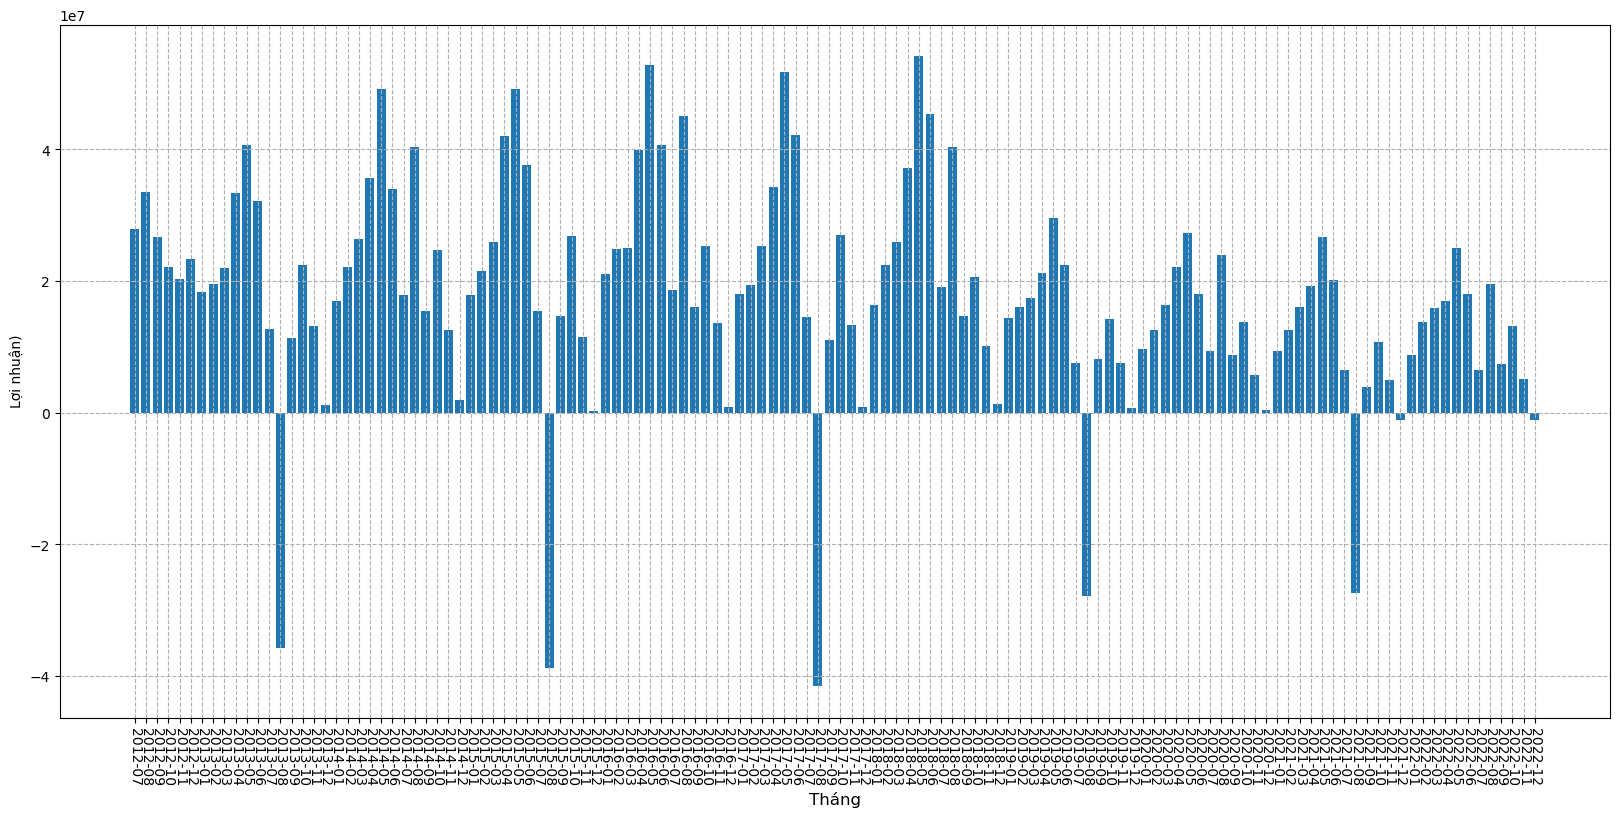

In [8]:
profitbyyearMonth = dfSale.groupby("yearMonth")["Profit"].sum()
pig, ax =  plt.subplots(figsize=(20, 9))
ax.bar(
    profitbyyearMonth.index,
    profitbyyearMonth.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

## Chương trình khuyến mại

In [10]:
dfPromotions = pd.read_csv("Master/promotions.csv")
dfPromotions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   promo_id             50 non-null     object 
 1   promo_name           50 non-null     object 
 2   promo_type           50 non-null     object 
 3   discount_value       50 non-null     float64
 4   start_date           50 non-null     object 
 5   end_date             50 non-null     object 
 6   applicable_category  10 non-null     object 
 7   promo_channel        50 non-null     object 
 8   stackable_flag       50 non-null     int64  
 9   min_order_value      50 non-null     int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 4.0+ KB


In [11]:
dfPromotions["start_date"] = pd.to_datetime(dfPromotions["start_date"])
dfPromotions["end_date"] = pd.to_datetime(dfPromotions["end_date"])
dfPromotions['year'] = dfPromotions['start_date'].dt.year
dfPromotions['month'] = dfPromotions['start_date'].dt.month
dfPromotions['duration'] = (dfPromotions['end_date'] - dfPromotions['start_date']).dt.days
dfPromotions["yearMonth"] = dfPromotions["start_date"].dt.strftime("%Y-%m")


In [12]:
dfPromotions

,promo_id,promo_name,promo_type,discount_value,start_date,end_date,applicable_category,promo_channel,stackable_flag,min_order_value,year,month,duration,yearMonth
0,PROMO-0001,Spring Sale 2013,percentage,12.0,2013-03-18,2013-04-17,NaN,email,1,0,2013,3,30,2013-03
1,PROMO-0002,Mid-Year Sale 2013,percentage,18.0,2013-06-23,2013-07-22,NaN,online,0,0,2013,6,29,2013-06
2,PROMO-0003,Fall Launch 2013,percentage,10.0,2013-08-30,2013-10-02,NaN,email,0,0,2013,8,33,2013-08
3,PROMO-0004,Year-End Sale 2013,percentage,20.0,2013-11-18,2014-01-02,NaN,all_channels,0,50000,2013,11,45,2013-11
4,PROMO-0005,Urban Blowout 2013,fixed,50.0,2013-07-30,2013-09-02,Streetwear,online,0,150000,2013,7,34,2013-07
5,PROMO-0006,Rural Special 2013,percentage,15.0,2013-01-31,2013-03-01,Outdoor,in_store,0,0,2013,1,29,2013-01
6,PROMO-0007,Spring Sale 2014,percentage,12.0,2014-03-18,2014-04-17,NaN,email,1,0,2014,3,30,2014-03
7,PROMO-0008,Mid-Year Sale 2014,percentage,18.0,2014-06-23,2014-07-22,NaN,social_media,0,0,2014,6,29,2014-06
8,PROMO-0009,Fall Launch 2014,percentage,10.0,2014-08-30,2014-10-01,NaN,all_channels,0,100000,2014,8,32,2014-08
9,PROMO-0010,Year-End Sale 2014,percentage,20.0,2014-11-19,2015-01-02,NaN,all_channels,0,100000,2014,11,44,2014-11


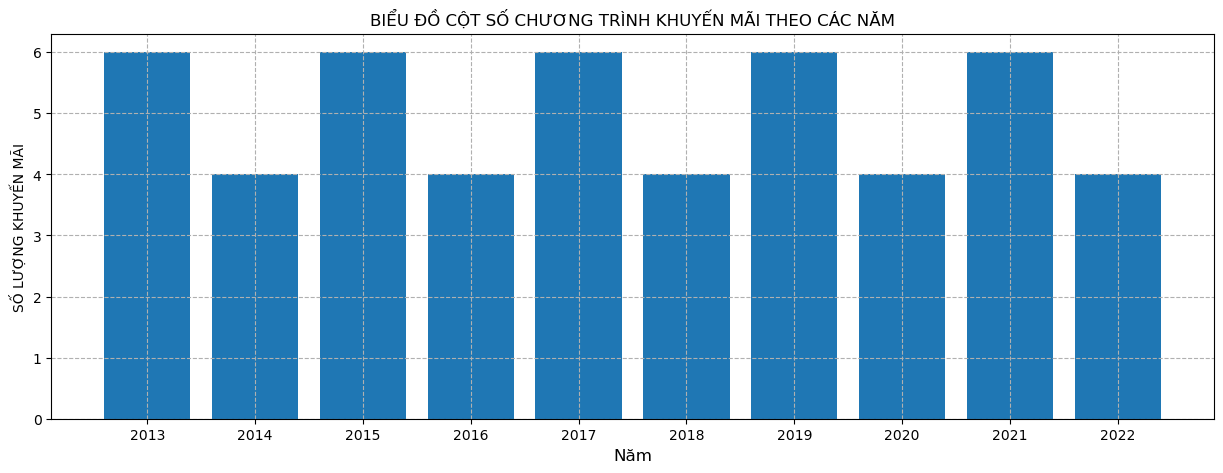

In [13]:
promo_per_year = dfPromotions.groupby(['year']).size()

pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    promo_per_year.index,
    promo_per_year.values
)
ax.set_title("BIỂU ĐỒ CỘT SỐ CHƯƠNG TRÌNH KHUYẾN MÃI THEO CÁC NĂM")
ax.set_ylabel('SỐ LƯỢNG KHUYẾN MÃI')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(promo_per_year.index),max(promo_per_year.index)+1))
plt.show()

In [14]:
promo_per_month = dfPromotions.groupby(['yearMonth'])["duration"].mean().reset_index().sort_values(by = ['yearMonth'])

In [15]:
datyStart = min(dfPromotions["yearMonth"])
datyLast  = max(dfPromotions["yearMonth"])
dates = pd.date_range(start=datyStart, end=datyLast, freq='MS')
dates = [d.strftime('%Y-%m') for d in dates]
dates = pd.DataFrame(dates, columns=['yearMonth'])

In [16]:
promo_per_month = pd.merge(dates, promo_per_month, on='yearMonth', how='left').fillna(0).sort_values(by = ['yearMonth'])

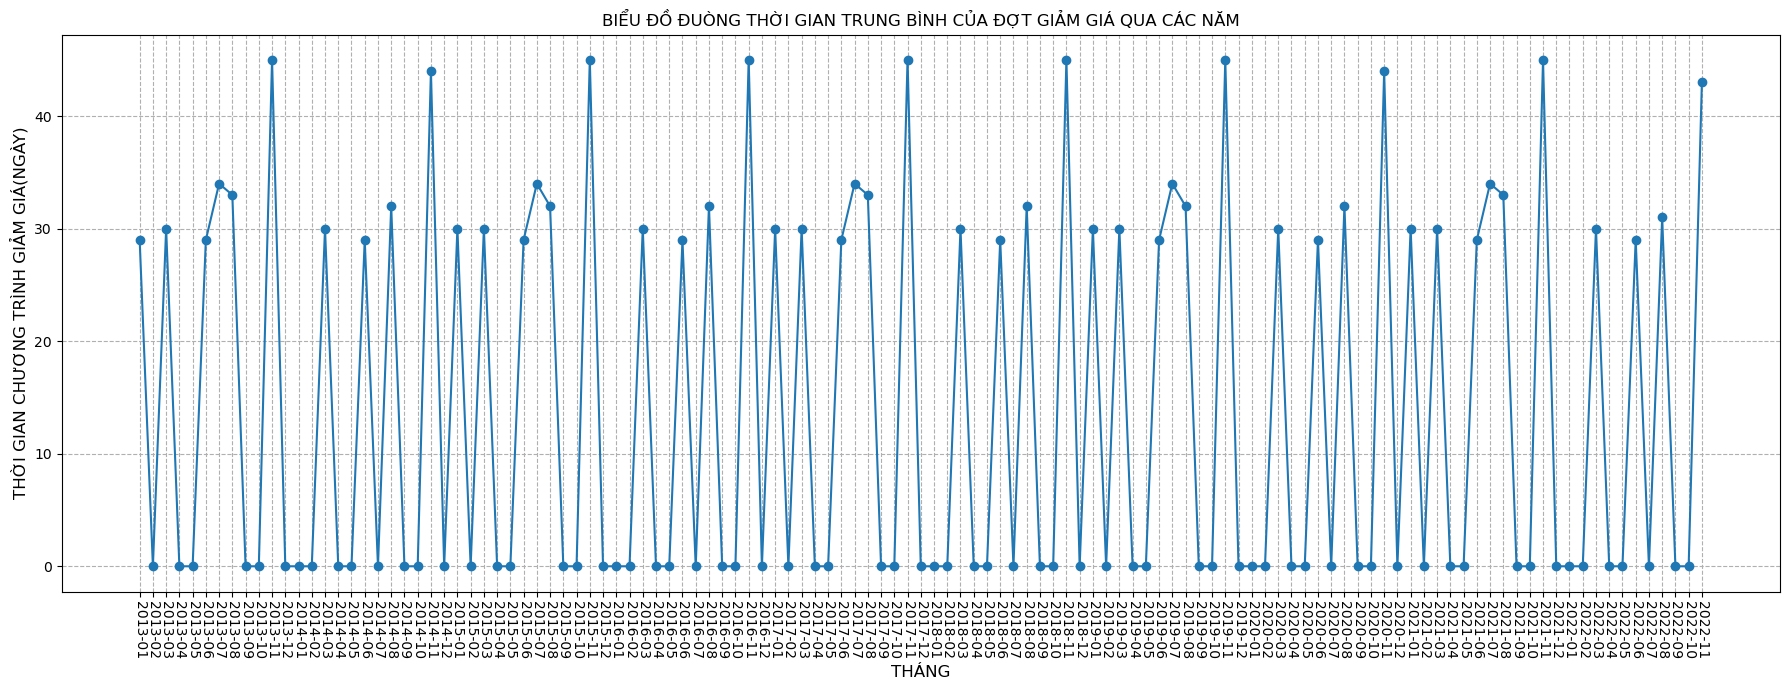

In [17]:
fig, ax = plt.subplots(figsize=(18, 7))
ax.plot(
    promo_per_month["yearMonth"].values,
    promo_per_month["duration"].values,
    marker = "o"
)
ax.grid(ls = "--")
ax.set_title("BIỂU ĐỒ ĐUÒNG THỜI GIAN TRUNG BÌNH CỦA ĐỢT GIẢM GIÁ QUA CÁC NĂM")
ax.set_ylabel('THỜI GIAN CHƯƠNG TRÌNH GIẢM GIÁ(NGÀY)', fontsize=12)
ax.set_xlabel('THÁNG', fontsize=12)
plt.xticks(rotation=270)
plt.tight_layout()

plt.show()

## SỐ LƯỢNG ĐƠN HÀNG

In [20]:
dfOrder_item = pd.read_csv("Transaction/order_items.csv")
dfOrder = pd.read_csv("Transaction/orders.csv")
dfOrder_item.info()

C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_1228\2142049474.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_item = pd.read_csv("Transaction/order_items.csv")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


In [26]:
dfOrder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        646945 non-null  int64         
 1   order_date      646945 non-null  datetime64[ns]
 2   customer_id     646945 non-null  int64         
 3   zip             646945 non-null  int64         
 4   order_status    646945 non-null  object        
 5   payment_method  646945 non-null  object        
 6   device_type     646945 non-null  object        
 7   order_source    646945 non-null  object        
 8   yearMonth       646945 non-null  object        
 9   year            646945 non-null  int32         
dtypes: datetime64[ns](1), int32(1), int64(3), object(5)
memory usage: 46.9+ MB


In [32]:
# Số lượng đơn hàng
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder["yearMonth"] = dfOrder["order_date"].dt.strftime("%Y-%m")
dfOrder["year"] = dfOrder["order_date"].dt.year
dfOrder["month"] = dfOrder["order_date"].dt.month


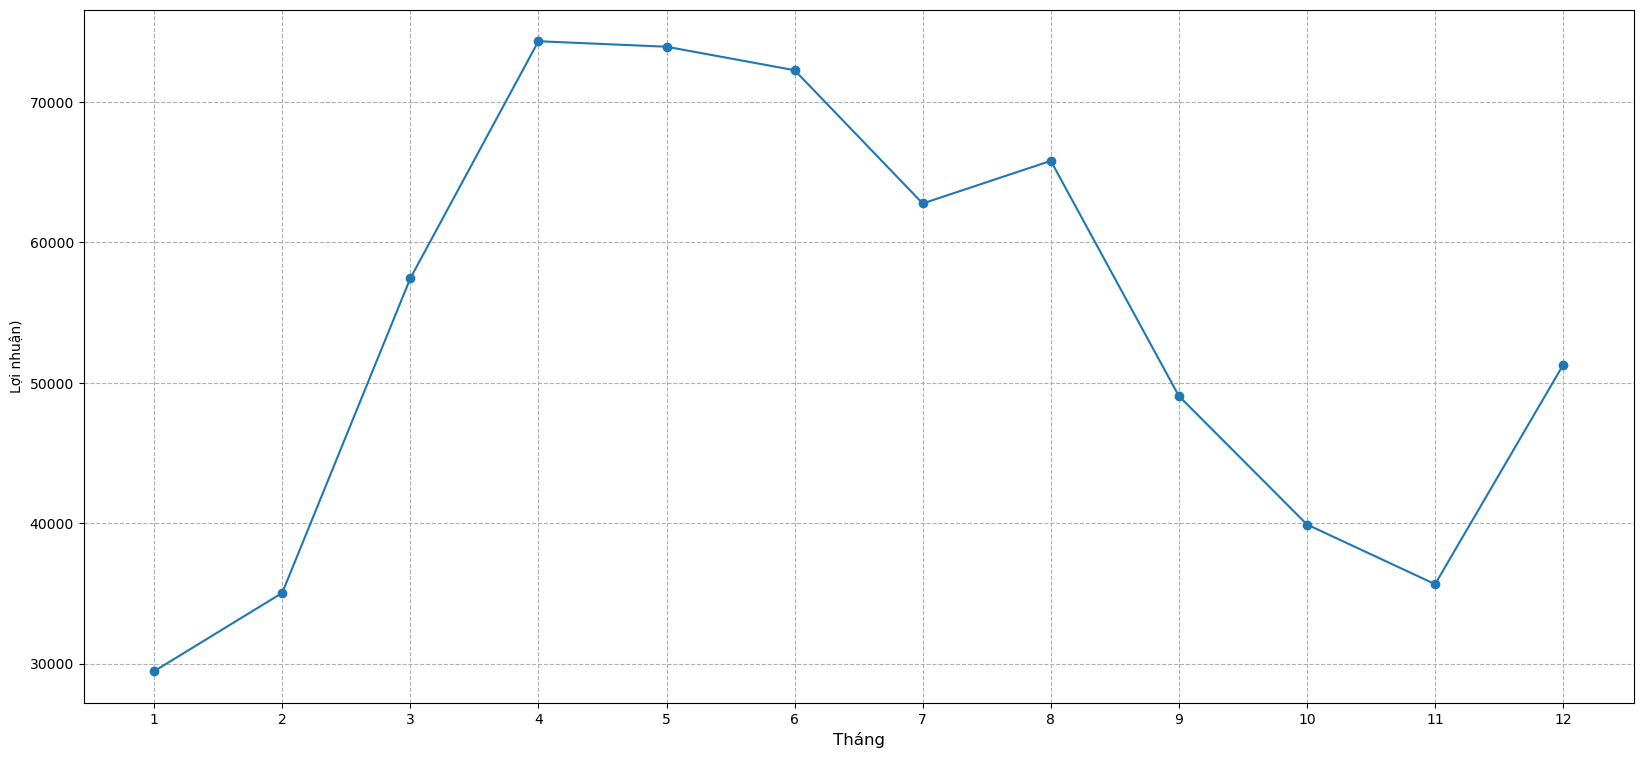

In [46]:
pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    dfOrder.groupby("month")["order_id"].count().index,
    dfOrder.groupby("month")["order_id"].count().values,
    marker = 'o'
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
# plt.xticks(rotation=270)
plt.xticks(range(1,13))  
ax.grid(ls = "--")

plt.show()

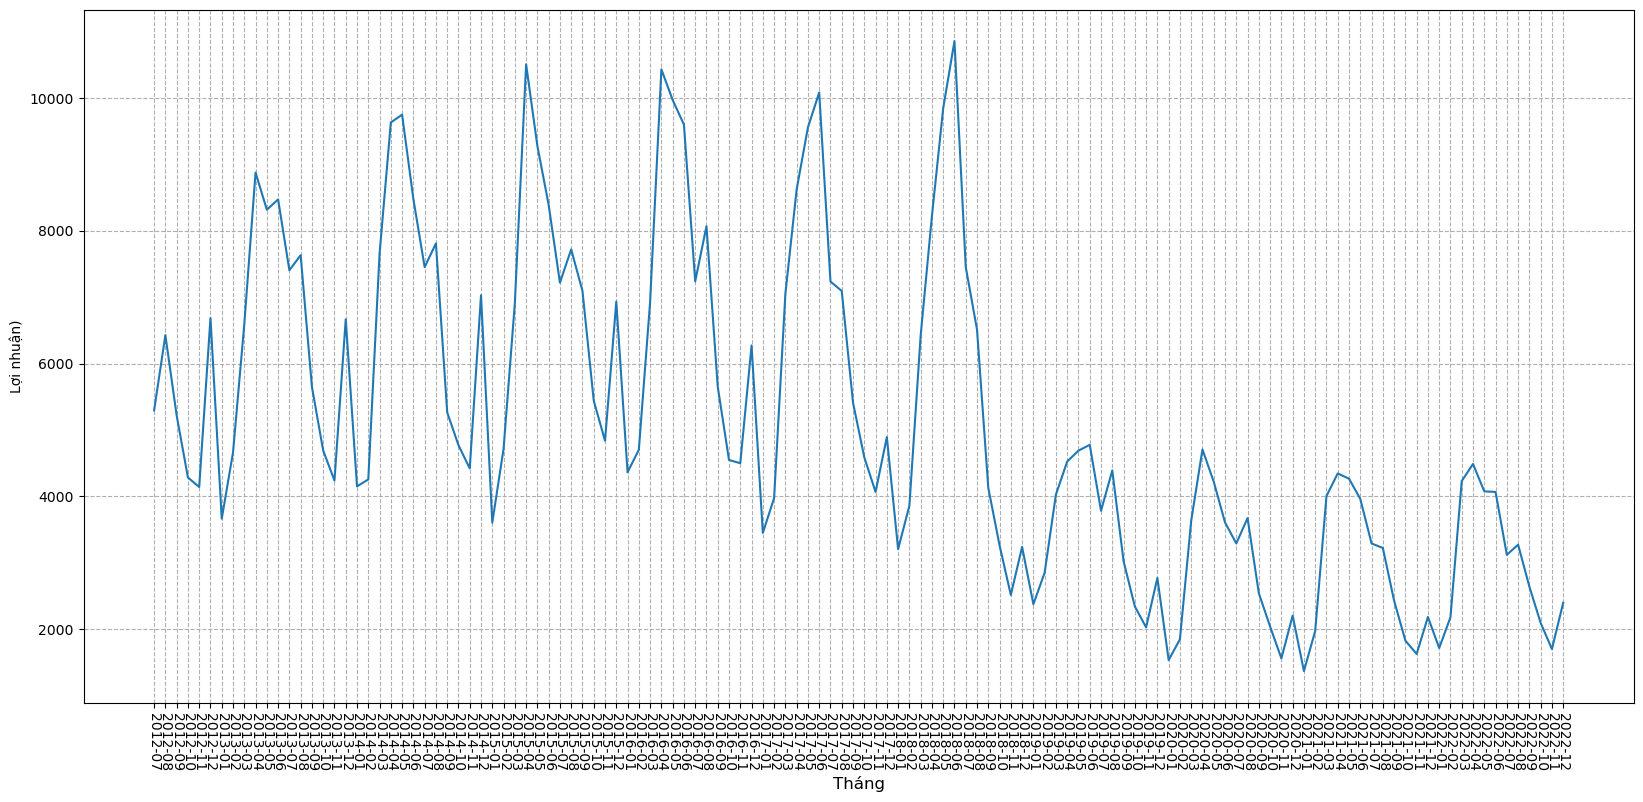

In [38]:
countOrder = dfOrder.groupby("yearMonth")["order_id"].count()

pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countOrder.index,
    countOrder.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

In [66]:
orderFull = pd.merge(dfOrder, dfOrder_item, on='order_id', how='left').sort_values(by = ['yearMonth'])

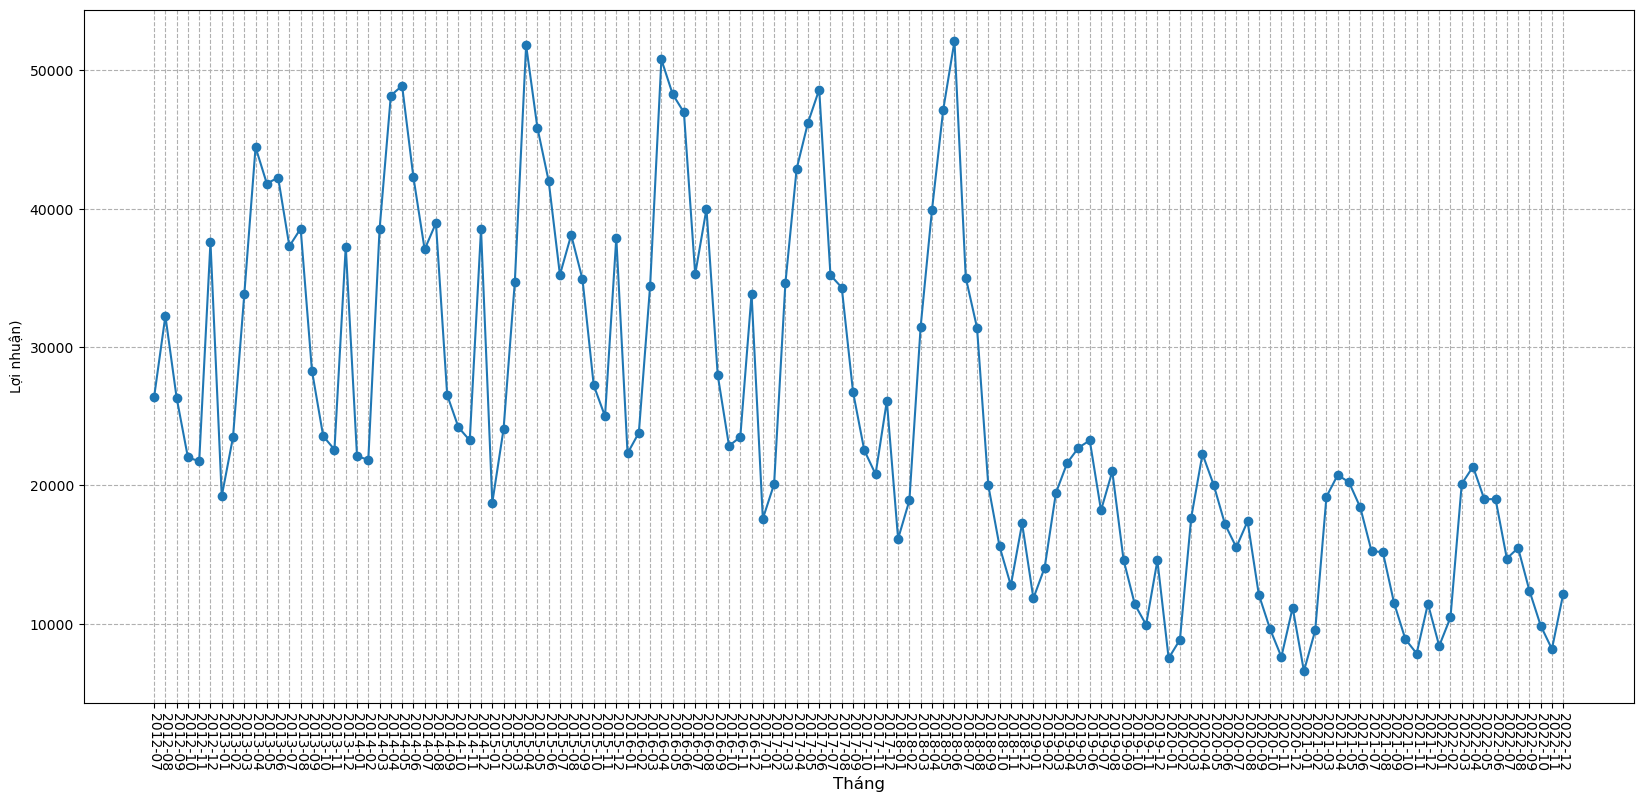

In [70]:
countQuantity = orderFull.groupby("yearMonth")["quantity"].sum()

pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countQuantity.index,
    countQuantity.values,
    marker = "o"
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

**Nhận xét**

- Tính mùa vụ cực cao sẵn sàng bán lỗ trong 1 khoảng thời gian

## SẢN PHẨM

## KHÁCH HÀNG VÀ VỊ TRÍ ĐỊA LÝ